# SESSION 10 - Data Visualization: Matplotlib (Part 1)

**Curriculum Module:** Data Collection, Cleaning, Visualization and Analysis  
**Session:** 10 - Data Visualization: Matplotlib (Part 1)  
**Status:** ✅ Completed

---

## 📋 Topics Covered
1. **Introduction to Matplotlib Architecture**: Figure canvas, Axes hierarchy, and explicit object-oriented API.
2. **Line Plots (`plt.plot()`)**: Visualizing sequential/trend data with markers, linewidths, and custom styling.
3. **Scatter Plots (`plt.scatter()`)**: Investigating bivariate correlations with point markers, alphas, and text annotations.
4. **Bar Charts (`plt.bar()`)**: Categorical comparisons with custom color palettes, data value labels, and multi-element legends.
5. **Histograms (`plt.hist()`)**: Estimating continuous probability distributions across custom bin ranges.
6. **Multi-Plot Figures (`plt.subplots()`)**: Combining multiple visual axes into cohesive composite dashboards and exporting high-resolution charts (`plt.savefig()`).


---

## Task 1: Daily Step Count Line Plot (`steps_lineplot.png`)

**Problem Statement:**  
*Install Matplotlib in your Python environment and create a simple line plot showing the number of daily steps you took over the last 7 days. Save the chart as `steps_lineplot.png`.*


Daily Steps Data:
   day        date  steps_count
0  Mon  2024-06-03         6500
1  Tue  2024-06-04         8200
2  Wed  2024-06-05         7800
3  Thu  2024-06-06         9100
4  Fri  2024-06-07        10500
5  Sat  2024-06-08        12400
6  Sun  2024-06-09         9800
Saved chart successfully as steps_lineplot.png


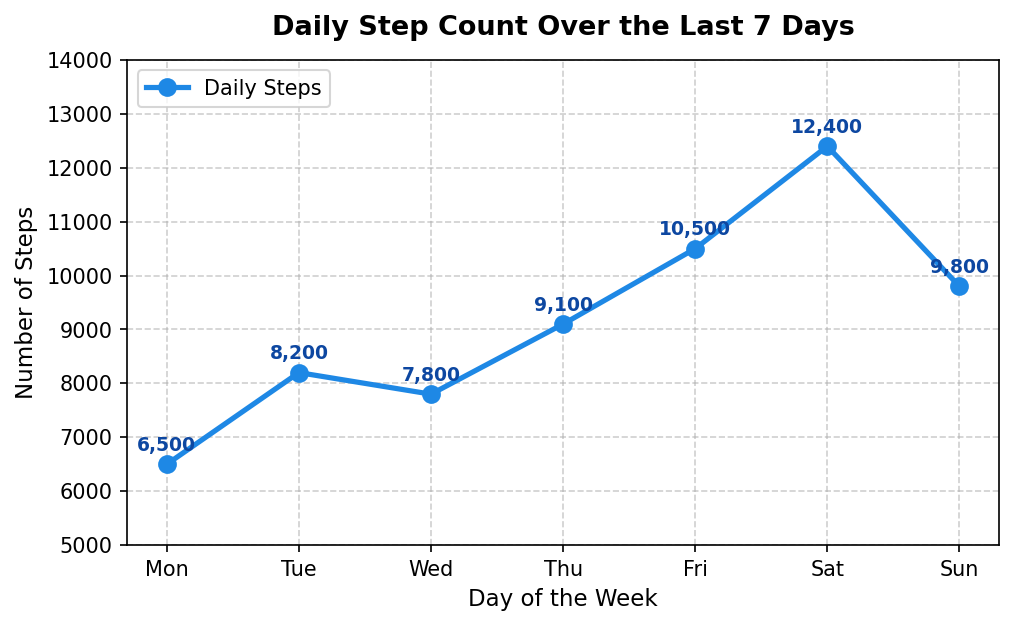

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

# Load 7-day daily step count data
df_steps = pd.read_csv('daily_steps.csv')
print('Daily Steps Data:')
print(df_steps)

# Create line plot
plt.figure(figsize=(7.5, 4.2), dpi=150)
plt.plot(
    df_steps['day'],
    df_steps['steps_count'],
    marker='o',
    color='#1E88E5',
    linewidth=2.5,
    markersize=8,
    label='Daily Steps'
)

# Add data value annotations for each day
for i, txt in enumerate(df_steps['steps_count']):
    plt.annotate(f'{txt:,}', (df_steps['day'][i], df_steps['steps_count'][i] + 250), ha='center', fontsize=9, fontweight='bold', color='#0D47A1')

plt.title('Daily Step Count Over the Last 7 Days', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Day of the Week', fontsize=11)
plt.ylabel('Number of Steps', fontsize=11)
plt.ylim(5000, 14000)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(loc='upper left')

# Save chart to disk
plt.savefig('steps_lineplot.png', bbox_inches='tight')
plt.show()
print('Saved chart successfully as steps_lineplot.png')


---

## Task 2: Restaurant Price vs Rating Scatter Plot

**Problem Statement:**  
*Using Matplotlib, create a scatter plot of 10 restaurants from your city with their Zomato ratings on the x-axis and average meal price on the y-axis. Add axis labels and a title to the chart.*


Restaurants Dataset (10 Entries):
     restaurant_name  rating  avg_meal_price
0           Truffles     4.5             800
1           Bawarchi     4.2             600
2          Peter Cat     4.4            1200
3           Bademiya     4.1             700
4            Karim's     4.3             900
5    Saravana Bhavan     4.6             400
6  Empire Restaurant     3.9             550
7      Meghana Foods     4.4             650
8   Glen's Bakehouse     4.2             750
9               Toit     4.7            1500


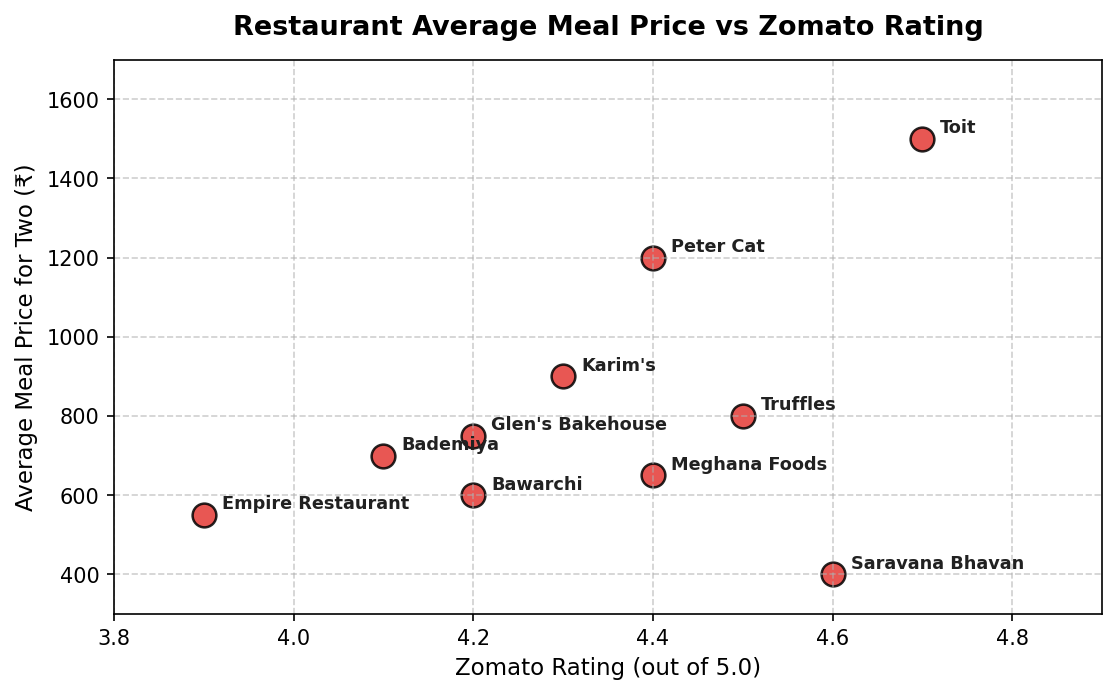

In [2]:
# Load Zomato restaurant ratings and meal price dataset
df_zomato = pd.read_csv('zomato_restaurants.csv')
print('Restaurants Dataset (10 Entries):')
print(df_zomato[['restaurant_name', 'rating', 'avg_meal_price']])

# Create scatter plot
plt.figure(figsize=(8.5, 4.8), dpi=150)
plt.scatter(
    df_zomato['rating'],
    df_zomato['avg_meal_price'],
    color='#E53935',
    s=130,
    alpha=0.85,
    edgecolors='black',
    linewidth=1.2,
    label='Restaurants'
)

# Annotate restaurant names adjacent to points
for i, row in df_zomato.iterrows():
    plt.annotate(row['restaurant_name'], (row['rating'] + 0.02, row['avg_meal_price'] + 15), fontsize=8.5, fontweight='bold', color='#212121')

plt.title('Restaurant Average Meal Price vs Zomato Rating', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Zomato Rating (out of 5.0)', fontsize=11)
plt.ylabel('Average Meal Price for Two (₹)', fontsize=11)
plt.xlim(3.8, 4.9)
plt.ylim(300, 1700)
plt.grid(True, linestyle='--', alpha=0.6)
plt.savefig('restaurant_scatter.png', bbox_inches='tight')
plt.show()


---

## Task 3: Monthly Food Delivery Orders Bar Chart with Legend

**Problem Statement:**  
*Build a bar chart that shows the number of orders you or your friends placed on Swiggy, Zomato, and Domino's in the last month. Use different colors for each bar and add a legend.*


Platform Order Records:
   platform  orders_count    color
0    Swiggy            18  #FC8019
1    Zomato            14  #CB202D
2  Domino's             6  #006491


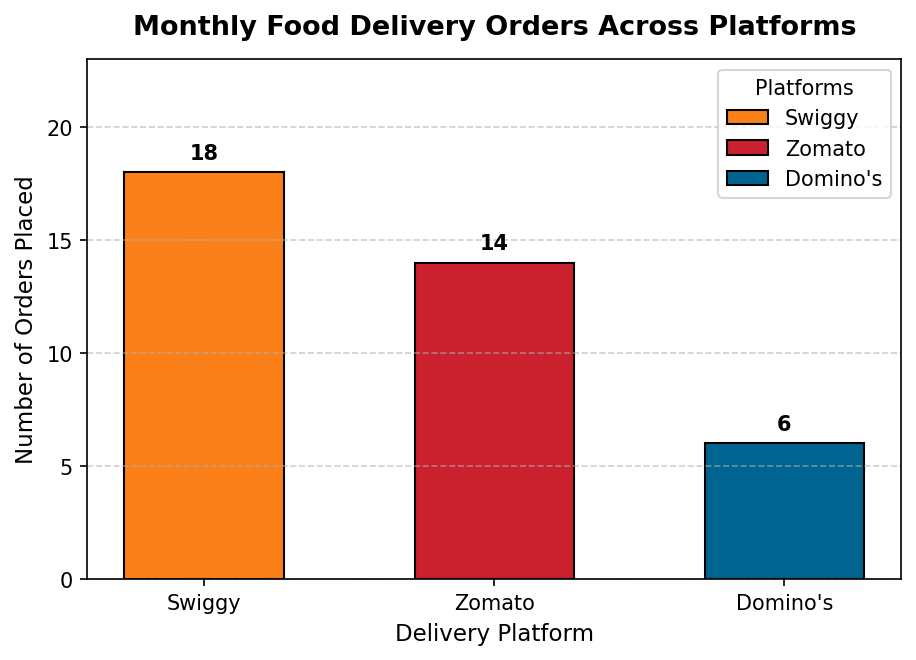

In [3]:
# Load delivery orders data
df_orders = pd.read_csv('food_delivery_orders.csv')
print('Platform Order Records:')
print(df_orders)

# Create bar chart with distinct colors per platform
plt.figure(figsize=(7, 4.5), dpi=150)
bars = plt.bar(
    df_orders['platform'],
    df_orders['orders_count'],
    color=df_orders['color'],
    width=0.55,
    edgecolor='black',
    linewidth=1
)

# Assign individual labels for legend display and add value labels on bars
for bar, label in zip(bars, df_orders['platform']):
    bar.set_label(label)
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 0.4, int(yval), ha='center', va='bottom', fontweight='bold', fontsize=10)

plt.title('Monthly Food Delivery Orders Across Platforms', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Delivery Platform', fontsize=11)
plt.ylabel('Number of Orders Placed', fontsize=11)
plt.ylim(0, max(df_orders['orders_count']) + 5)
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.legend(title='Platforms', loc='upper right')

plt.savefig('food_delivery_barchart.png', bbox_inches='tight')
plt.show()


---

## Task 4: Spotify Session Duration Histogram (5 Bins)

**Problem Statement:**  
*Create a histogram of the durations (in minutes) of your last 20 Spotify listening sessions using Matplotlib. Set the number of bins to 5 and customize the color of the bars.*


Spotify Sessions Duration Summary (20 Sessions):
count    20.00
mean     36.95
std      15.80
min      12.00
25%      24.25
50%      36.50
75%      48.50
max      65.00


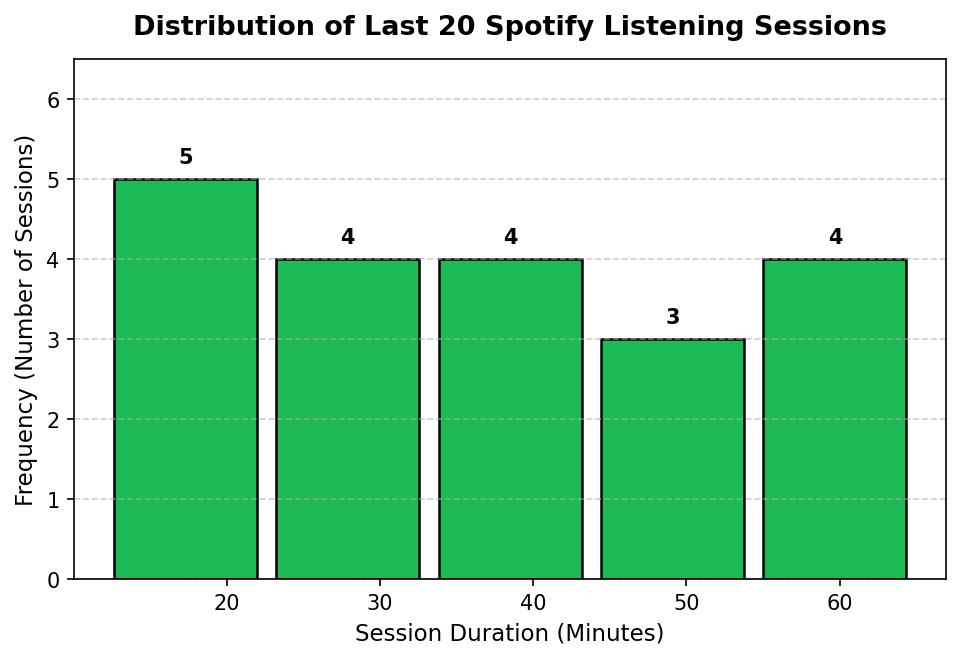

In [4]:
# Load Spotify session durations dataset (20 records)
df_spotify = pd.read_csv('spotify_sessions.csv')
print(f'Spotify Sessions Duration Summary (20 Sessions):')
print(df_spotify['duration_minutes'].describe().round(2))

# Generate histogram with 5 bins and customized Spotify green bar color
plt.figure(figsize=(7.5, 4.5), dpi=150)
n, bins, patches = plt.hist(
    df_spotify['duration_minutes'],
    bins=5,
    color='#1DB954',
    edgecolor='black',
    linewidth=1.2,
    rwidth=0.88
)

# Add frequency labels atop each histogram bin
for i in range(len(n)):
    if n[i] > 0:
        bin_center = (bins[i] + bins[i+1]) / 2.0
        plt.text(bin_center, n[i] + 0.15, int(n[i]), ha='center', va='bottom', fontweight='bold', fontsize=10)

plt.title('Distribution of Last 20 Spotify Listening Sessions', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Session Duration (Minutes)', fontsize=11)
plt.ylabel('Frequency (Number of Sessions)', fontsize=11)
plt.ylim(0, max(n) + 1.5)
plt.grid(axis='y', linestyle='--', alpha=0.6)

plt.savefig('spotify_session_histogram.png', bbox_inches='tight')
plt.show()


---

## Task 5: Multi-Plot Dashboard with Subplots (`social_media_usage.png`)

**Problem Statement:**  
*Customize a Matplotlib figure by creating a plot with two subplots: one line plot showing your daily Instagram screen time for a week, and one bar chart showing the number of posts you liked each day. Add appropriate titles, axis labels, and save the figure as `social_media_usage.png`.*  
*Hint: Use `plt.subplots()` to create multiple axes in one figure.*


Weekly Instagram Analytics:
   day  screen_time_mins  posts_liked
0  Mon                45           18
1  Tue                60           25
2  Wed                55           20
3  Thu                75           32
4  Fri                90           40
5  Sat               130           55
6  Sun               110           48
Saved figure successfully as social_media_usage.png


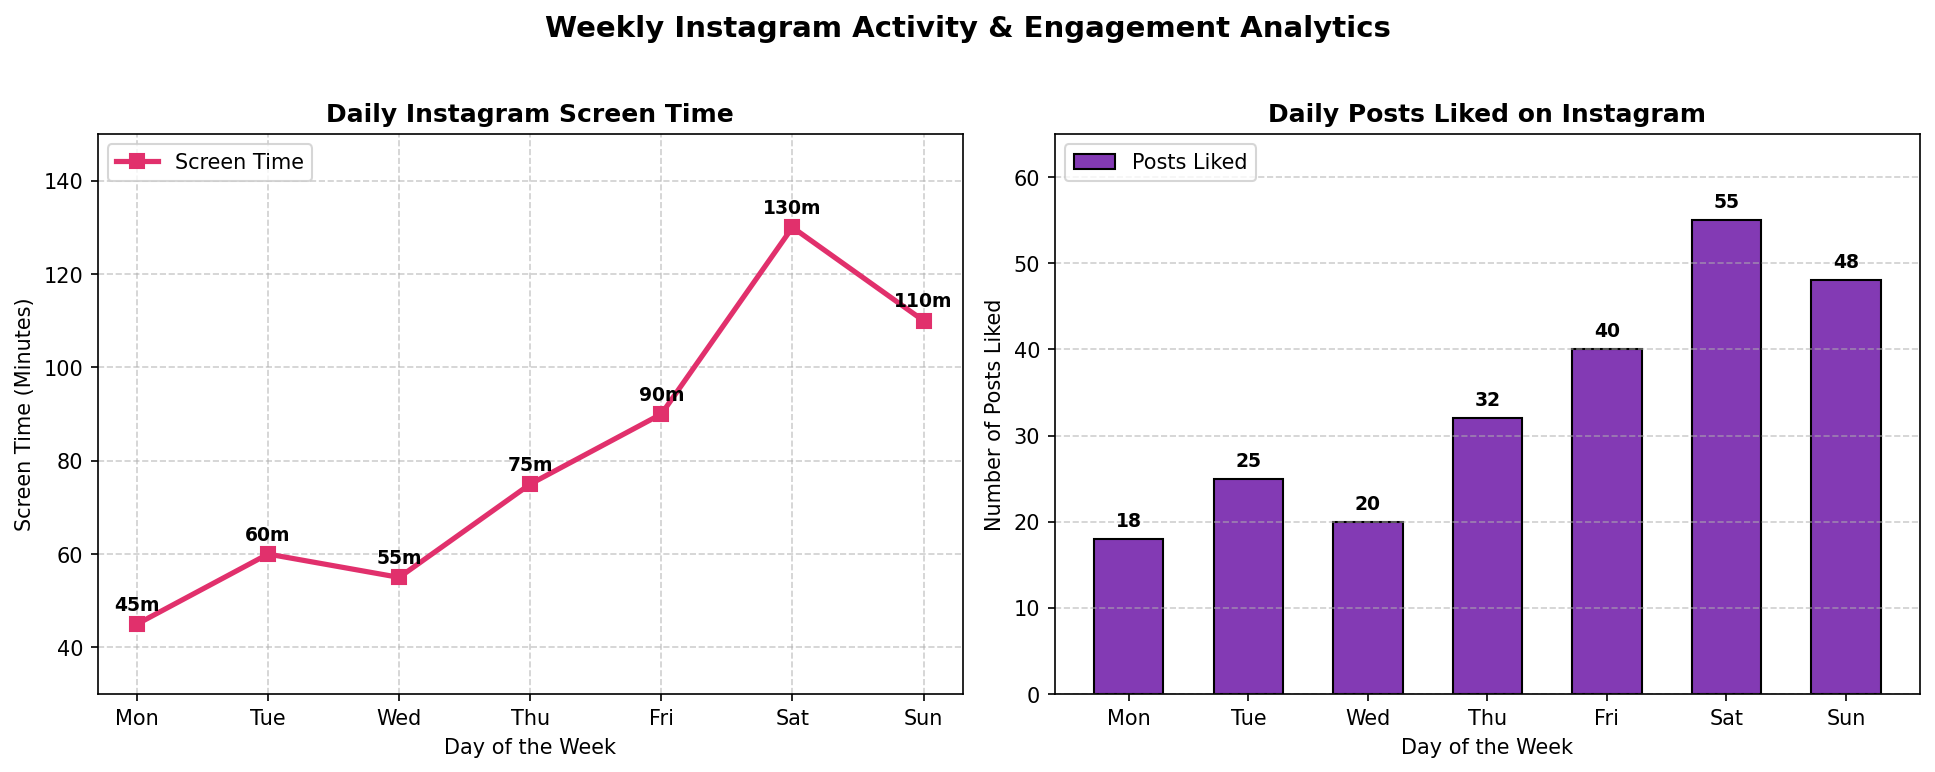

In [5]:
# Load Instagram weekly usage dataset
df_insta = pd.read_csv('instagram_usage.csv')
print('Weekly Instagram Analytics:')
print(df_insta)

# Initialize figure with 1 row and 2 subplots
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5), dpi=150)

# Subplot 1: Daily Screen Time Line Plot
ax1.plot(
    df_insta['day'],
    df_insta['screen_time_mins'],
    marker='s',
    color='#E1306C',
    linewidth=2.5,
    markersize=7,
    label='Screen Time'
)
for i, txt in enumerate(df_insta['screen_time_mins']):
    ax1.annotate(f'{txt}m', (df_insta['day'][i], df_insta['screen_time_mins'][i] + 3), ha='center', fontsize=9, fontweight='bold')
ax1.set_title('Daily Instagram Screen Time', fontsize=12, fontweight='bold')
ax1.set_xlabel('Day of the Week', fontsize=10)
ax1.set_ylabel('Screen Time (Minutes)', fontsize=10)
ax1.set_ylim(30, 150)
ax1.grid(True, linestyle='--', alpha=0.6)
ax1.legend(loc='upper left')

# Subplot 2: Posts Liked Bar Chart
bars2 = ax2.bar(df_insta['day'], df_insta['posts_liked'], color='#833AB4', edgecolor='black', width=0.58, label='Posts Liked')
for bar in bars2:
    yval = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2.0, yval + 1, int(yval), ha='center', va='bottom', fontweight='bold', fontsize=9)
ax2.set_title('Daily Posts Liked on Instagram', fontsize=12, fontweight='bold')
ax2.set_xlabel('Day of the Week', fontsize=10)
ax2.set_ylabel('Number of Posts Liked', fontsize=10)
ax2.set_ylim(0, max(df_insta['posts_liked']) + 10)
ax2.grid(axis='y', linestyle='--', alpha=0.6)
ax2.legend(loc='upper left')

# Global Title & Layout Optimization
fig.suptitle('Weekly Instagram Activity & Engagement Analytics', fontsize=14, fontweight='bold', y=1.02)
fig.tight_layout()

# Save figure as required
fig.savefig('social_media_usage.png', bbox_inches='tight')
plt.show()
print('Saved figure successfully as social_media_usage.png')


---

## 🎯 Key Takeaways & Best Practices
- **State-based vs. Object-Oriented Interface**: While `plt.plot()` is convenient for quick prototypes, the object-oriented approach (`fig, ax = plt.subplots()`) provides granular layout control across complex multi-panel dashboards.
- **Visual Hierarchy & Clutter Reduction**: Enhance charts by combining subtle grid lines (`linestyle='--'`, `alpha=0.6`), explicit value annotations (`plt.annotate()` / `plt.text()`), and intentional axis padding (`ylim`).
- **Meaningful Color Semantics**: Use brand colors (`#FC8019` for Swiggy, `#CB202D` for Zomato, `#1DB954` for Spotify) and contrasting edges (`edgecolor='black'`) to make visual elements instantly identifiable.
- **High-Resolution Exports**: Always supply `dpi=150` (or `300` for print) and `bbox_inches='tight'` to `plt.savefig()` to prevent truncated axis labels and ensure crystal-clear visual reports.
